<a href="https://colab.research.google.com/github/jorge-gch/deblurring/blob/main/image_deblurring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Single Image Deblurring Problem**

Image deblurring is an inverse problem in which the observed image $\mathbf{y}$ is a blurred version of the clean image $\mathbf{x}$:

$$
\mathbf{y}=\mathbf{h}\otimes\mathbf{x},
$$

where $\mathbf{h}$ is a blur kernel and $\otimes$ denotes convolution. In this notebook, the degradation is a fixed Gaussian point-spread function (PSF).

### **Objective**
Develop a deep-learning model that estimates $\hat{\mathbf{x}}=f_\theta(\mathbf{y})$ from blurred observations.

### **Experimental protocol**
- Dataset: BSDS500, matching the other image-restoration projects.
- Training crops: $96\times96$ with random crop and horizontal flip.
- Validation crop: centered $288\times288$.
- Fixed degradation for comparability: Gaussian blur, kernel $9\times9$, $\sigma=2.0$.
- Backbone: same compact residual CNN family used in the other projects.
- Loss: MSE by default.
- Metrics: PSNR and SSIM.
- Validation uses inference mode and the best validation checkpoint is restored.
- The blurred input itself is reported as a baseline.

### **Activities**
1. Improve the baseline performance by changing optimization, loss, capacity, augmentation, or architecture.
2. Compare the restored result against the blurred-input baseline.
3. Document quantitative and visual results in an academic report.


# **Improvement Difficulty Levels**

To improve the baseline model, use the following difficulty guide.

## **Fixed components (cannot be changed)**
- **Dataset:** keep the BSDS500 dataset exactly as provided.
- **Corruption process:** keep the provided deblurring corruption process fixed. Do not remove it, replace it, or redesign it.

## **Allowed modifications**
You may improve the model by modifying the training pipeline and/or the neural network, for example:
- hyperparameter tuning
- preprocessing choices
- optimizer and learning-rate strategy
- loss function
- regularization
- weight initialization
- neural network architecture

## **Level 1 — Easy**
Focus on **hyperparameter tuning**. Examples:
- change batch size
- change the number of epochs
- change the learning rate
- change the number of filters
- change the number of residual blocks

## **Level 2 — Medium**
Modify the **training recipe** while keeping the general baseline architecture. Examples:
- compare optimizers (Adam, AdamW, RMSprop, etc.)
- test different losses (MSE, MAE/L1, weighted combinations)
- add regularization such as weight decay or dropout if justified
- improve preprocessing or data augmentation
- test learning-rate scheduling

## **Level 3 — Hard**
Modify the **neural network architecture**. Examples:
- deepen the network
- widen the network
- redesign the residual blocks
- add skip connections
- build a different CNN restoration architecture for the same task

## **Recommendation**
Start with a Level 1 improvement, verify whether PSNR/SSIM improve, and then move to Level 2 or Level 3 if needed. For every modification, explain **what changed**, **why it may help**, and **how the metrics and restored images changed**.


In [1]:
#@title Import libraries and set reproducibility
!pip -q install torchmetrics

import os
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torch.optim import SGD, Adam, RMSprop, AdamW #importé a AdamW
from torchmetrics.functional.image import peak_signal_noise_ratio
from torchmetrics.functional.image import structural_similarity_index_measure

from torch.optim.lr_scheduler import CosineAnnealingLR #importo para el scheduler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Device:', device)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 20.7 MB/s eta 0:00:00
Device: cuda:0


In [2]:
#@title Download BSDS500 Training and Validation Dataset
# Same dataset source used by the original Super-Resolution and Inpainting notebooks.
!wget --load-cookies /tmp/cookies.txt "https://docs.google.com/uc?export=download&confirm=$(wget --quiet --save-cookies /tmp/cookies.txt --keep-session-cookies --no-check-certificate 'https://docs.google.com/uc?export=download&id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC' -O- | sed -rn 's/.*confirm=([0-9A-Za-z_]+).*/\1\n/p')&id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC" -O BSDS500.zip && rm -rf /tmp/cookies.txt
!mkdir -p /content/BSDS500
!unzip -q -o BSDS500.zip -d /content/BSDS500

print('Dataset folders:', os.listdir('/content/BSDS500'))


--2026-10-20 00:01:44--  https://docs.google.com/uc?export=download&confirm=&id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC
Resolving docs.google.com (docs.google.com)... 74.125.195.139, 74.125.195.100, 74.125.195.102, ...
Connecting to docs.google.com (docs.google.com)|74.125.195.139|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC&export=download [following]
--2026-10-20 00:01:44--  https://drive.usercontent.google.com/download?id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 173.194.203.132, 2607:f8b0:400e:c05::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|173.194.203.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 22232532 (21M) [application/octet-stream]
Saving to: ‘BSDS500.zip’

BSDS500.zip         100%[===================>]  21.20M  --.-K

In [3]:
#@title Utility functions
class AverageMeter:
    def __init__(self):
        self.reset()

    def reset(self):
        self.avg = 0.0
        self.sum = 0.0
        self.count = 0

    def update(self, val, n=1):
        self.sum += float(val) * n
        self.count += n
        self.avg = self.sum / max(self.count, 1)


def read_rgb_file(filename):
    return Image.open(filename).convert('RGB')


def compute_metrics(pred, target):
    # Metrics are evaluated in the physical image range [0, 1].
    pred = pred.clamp(0.0, 1.0)
    target = target.clamp(0.0, 1.0)
    psnr = peak_signal_noise_ratio(pred, target, data_range=1.0)
    ssim = structural_similarity_index_measure(pred, target, data_range=1.0)
    return psnr.item(), ssim.item()


def show_tensor(img, ax=None, title=None):
    img = img.detach().cpu().clamp(0, 1).permute(1, 2, 0).numpy()
    if ax is None:
        plt.imshow(img)
        plt.axis('off')
        if title:
            plt.title(title)
    else:
        ax.imshow(img)
        ax.axis('off')
        if title:
            ax.set_title(title)


In [4]:
#@title Gaussian blur corruption (fixed inverse problem)
class CorruptionProcess:
    def __init__(self, kernel_size=9, sigma=2.0):
        if kernel_size % 2 == 0:
            raise ValueError('kernel_size must be odd')
        self.kernel_size = kernel_size
        self.sigma = float(sigma)

        coords = torch.arange(kernel_size, dtype=torch.float32) - kernel_size // 2
        g = torch.exp(-(coords ** 2) / (2 * self.sigma ** 2))
        g = g / g.sum()
        kernel_2d = torch.outer(g, g)
        self.kernel = kernel_2d[None, None, :, :]

    def __call__(self, x, idx=None):
        # x: (C, H, W), CPU tensor in [0,1]
        c = x.shape[0]
        kernel = self.kernel.repeat(c, 1, 1, 1)
        r = self.kernel_size // 2
        x_pad = F.pad(x.unsqueeze(0), (r, r, r, r), mode='reflect')
        y = F.conv2d(x_pad, kernel, groups=c).squeeze(0)
        return y
BLUR_KERNEL_SIZE = 9  # fixed for the baseline experiment
BLUR_SIGMA = 2.0      # fixed for the baseline experiment


In [5]:
#@title Dataset loader
class PairedRestorationDataset(Dataset):
    def __init__(self, data_path, transform, corruption):
        self.data_path = data_path
        self.imgs_names = sorted([
            f for f in os.listdir(data_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])
        self.transform = transform
        self.corruption = corruption

    def __len__(self):
        return len(self.imgs_names)

    def __getitem__(self, idx):
        path = os.path.join(self.data_path, self.imgs_names[idx])
        x = self.transform(read_rgb_file(path))
        y = self.corruption(x, idx)
        return x, y


def load_data(data_path, batch_size=4, train_size=96, val_size=288):
    train_transform = transforms.Compose([
        transforms.RandomCrop(train_size),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.ToTensor(),
    ])
    eval_transform = transforms.Compose([
        transforms.CenterCrop(val_size),
        transforms.ToTensor(),
    ])

    train_corruption = CorruptionProcess(BLUR_KERNEL_SIZE, BLUR_SIGMA)
    eval_corruption = CorruptionProcess(BLUR_KERNEL_SIZE, BLUR_SIGMA)


    train_dir = os.path.join(data_path, 'train')
    val_dir = os.path.join(data_path, 'val')
    test_dir = os.path.join(data_path, 'test')

    train_ds = PairedRestorationDataset(train_dir, train_transform, train_corruption)
    val_ds = PairedRestorationDataset(val_dir, eval_transform, eval_corruption)
    test_ds = PairedRestorationDataset(test_dir, eval_transform, eval_corruption) if os.path.isdir(test_dir) else None

    loader_kwargs = dict(num_workers=2, pin_memory=torch.cuda.is_available())
    g = torch.Generator().manual_seed(SEED)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=g, **loader_kwargs)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, **loader_kwargs)
    test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, **loader_kwargs) if test_ds is not None else None
    return train_loader, val_loader, test_loader


In [6]:
#@title Deep Neural Network Architecture
class ResidualBlock(nn.Module):
    def __init__(self, channels, res_scale=0.1):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, 1, 1)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(channels, channels, 3, 1, 1)
        self.res_scale = res_scale  # estabiliza el entrenamiento con redes más anchas

    def forward(self, x):
        return x + self.res_scale * self.conv2(self.relu(self.conv1(x)))


class DeepNeuralNetwork(nn.Module):
    def __init__(self, num_channels=3, base_filter=64, num_residuals=8):
        super().__init__()
        self.head = nn.Conv2d(num_channels, base_filter, 3, 1, 1, padding_mode='reflect')
        self.body = nn.Sequential(*[ResidualBlock(base_filter) for _ in range(num_residuals)])
        self.body_conv = nn.Conv2d(base_filter, base_filter, 3, 1, 1)
        self.tail = nn.Conv2d(base_filter, num_channels, 3, 1, 1)  # 3x3 en vez de 1x1

        # Arranca como la identidad: el PSNR inicial ya es el de la imagen borrosa
        nn.init.zeros_(self.tail.weight)
        nn.init.zeros_(self.tail.bias)

    def forward(self, y):
        f0 = self.head(y)
        f = self.body_conv(self.body(f0)) + f0   # skip connection larga
        return y + self.tail(f)                  # skip connection global: la red predice solo el detalle que falta


In [7]:
#@title Model hyperparameters, optimizer, and loss
#original=50
EPOCHS = 150  #@param
# original=4
BATCH_SIZE = 4 #@param
#original=8
base_filter = 64 #@param
#original=3
num_residuals = 12 #@param


model = DeepNeuralNetwork(base_filter=base_filter, num_residuals=num_residuals).to(device)

optimizer_name = 'AdamW' #@param ["SGD", "Adam","AdamW", "RMSprop"] {type:"string"}
cost_function = 'L1+SSIM' #@param ["MSE", "MAE", "L1+SSIM"] {type:"string"}
learning_rate = 1e-3 #@param

if optimizer_name == 'SGD':
    optimizer = SGD(model.parameters(), lr=learning_rate, momentum=0.9, weight_decay=1e-9)
elif optimizer_name == 'Adam':
    optimizer = Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)#original 1e-9
elif optimizer_name == 'AdamW':#añadi a AdamW
    optimizer = AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
elif optimizer_name == 'RMSprop':
    optimizer = RMSprop(model.parameters(), lr=learning_rate, weight_decay=1e-9)
else:
    raise ValueError('Unknown optimizer')

#criterion = nn.MSELoss() if cost_function == 'MSE' else nn.L1Loss()
SSIM_WEIGHT = 0.1 #@param
class L1SSIMLoss(nn.Module):
    def __init__(self, ssim_weight=0.1):
        super().__init__()
        self.ssim_weight = ssim_weight

    def forward(self, pred, target):
        l1 = F.l1_loss(pred, target)
        ssim = structural_similarity_index_measure(pred, target, data_range=1.0)
        return l1 + self.ssim_weight * (1 - ssim)

if cost_function == 'MSE':
    criterion = nn.MSELoss()
elif cost_function == 'MAE':
    criterion = nn.L1Loss()
else:
    criterion = L1SSIMLoss(SSIM_WEIGHT)


scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters: {n_params:,}')

CHECKPOINT_PATH = "/content/best_deblurring_model.pt"


Trainable parameters: 926,723


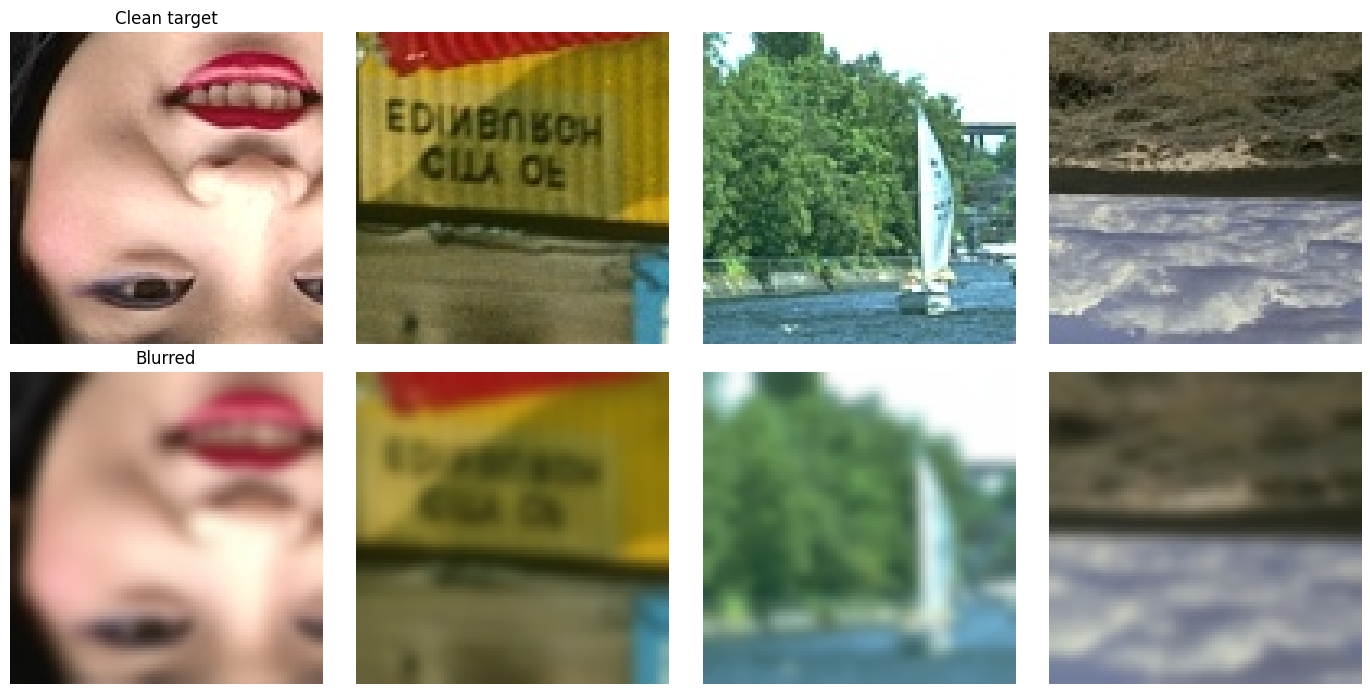

Gaussian blur: kernel 9x9 | sigma=2.0
Train batches: 50 | Validation images: 100
Independent test set: not available in this dataset package


In [8]:
#@title Load dataset and visualize samples
data_path = '/content/BSDS500'
train_loader, val_loader, test_loader = load_data(data_path, batch_size=BATCH_SIZE)

x, y = next(iter(train_loader))
num_imgs = min(4, x.size(0))
fig, axs = plt.subplots(2, num_imgs, figsize=(14, 7))
for i in range(num_imgs):
    show_tensor(x[i], axs[0, i], 'Clean target' if i == 0 else None)
    show_tensor(y[i], axs[1, i], 'Blurred' if i == 0 else None)
plt.tight_layout()
plt.show()

print(f'Gaussian blur: kernel {BLUR_KERNEL_SIZE}x{BLUR_KERNEL_SIZE} | sigma={BLUR_SIGMA:.1f}')
print('Train batches:', len(train_loader), '| Validation images:', len(val_loader))
print('Independent test set:', 'available' if test_loader is not None else 'not available in this dataset package')


In [9]:
#@title Baseline vs restored-image evaluation
def evaluate(loader, model=None):
    loss_m, psnr_m, ssim_m = AverageMeter(), AverageMeter(), AverageMeter()

    if model is not None:
        model.eval()

    with torch.inference_mode():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            pred = y if model is None else model(y)
            loss = criterion(pred, x)
            psnr_val, ssim_val = compute_metrics(pred, x)

            n = x.size(0)
            loss_m.update(loss.item(), n)
            psnr_m.update(psnr_val, n)
            ssim_m.update(ssim_val, n)

    return {'loss': loss_m.avg, 'psnr': psnr_m.avg, 'ssim': ssim_m.avg}

# Baseline before training (validation)
baseline_pre = evaluate(val_loader, model=None)
print(f"Blurred-input validation baseline | PSNR {baseline_pre['psnr']:.2f} dB | SSIM {baseline_pre['ssim']:.3f}")


Blurred-input validation baseline | PSNR 24.15 dB | SSIM 0.637


In [10]:
#@title Training process with validation and best-model checkpoint
history = {
    'train_loss': [], 'train_psnr': [], 'train_ssim': [],
    'val_loss': [], 'val_psnr': [], 'val_ssim': []
}

best_val_psnr = -float('inf')
best_state = None

for epoch in range(EPOCHS):
    losses, psnr_m, ssim_m = AverageMeter(), AverageMeter(), AverageMeter()
    val_losses, val_psnr_m, val_ssim_m = AverageMeter(), AverageMeter(), AverageMeter()

    model.train()
    for x, y in train_loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        x_hat = model(y)
        loss = criterion(x_hat, x)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)#agrego esto para estabilizar
        optimizer.step()

        with torch.no_grad():
            psnr_val, ssim_val = compute_metrics(x_hat, x)

        n = x.size(0)
        losses.update(loss.item(), n)
        psnr_m.update(psnr_val, n)
        ssim_m.update(ssim_val, n)

    model.eval()
    with torch.inference_mode():
        for x, y in val_loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            x_hat = model(y)

            loss = criterion(x_hat, x)
            psnr_val, ssim_val = compute_metrics(x_hat, x)

            n = x.size(0)
            val_losses.update(loss.item(), n)
            val_psnr_m.update(psnr_val, n)
            val_ssim_m.update(ssim_val, n)

    scheduler.step()#añadi este scheduler para ir bajando el learning rate

    history['train_loss'].append(losses.avg)
    history['train_psnr'].append(psnr_m.avg)
    history['train_ssim'].append(ssim_m.avg)
    history['val_loss'].append(val_losses.avg)
    history['val_psnr'].append(val_psnr_m.avg)
    history['val_ssim'].append(val_ssim_m.avg)

    if val_psnr_m.avg > best_val_psnr:
        best_val_psnr = val_psnr_m.avg
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, CHECKPOINT_PATH)

    print(
        f'Epoch {epoch+1:03d}/{EPOCHS} | '
        f'Loss {losses.avg:.7f} | PSNR {psnr_m.avg:.2f} | SSIM {ssim_m.avg:.3f} | '
        f'Val Loss {val_losses.avg:.7f} | Val PSNR {val_psnr_m.avg:.2f} | Val SSIM {val_ssim_m.avg:.3f}'
    )

model.load_state_dict(best_state)
print(f'Best validation PSNR: {best_val_psnr:.2f} dB')
print('Best checkpoint:', CHECKPOINT_PATH)


Epoch 001/150 | Loss 0.0764333 | PSNR 24.09 | SSIM 0.662 | Val Loss 0.0683036 | Val PSNR 25.12 | Val SSIM 0.699
Epoch 002/150 | Loss 0.0582062 | PSNR 25.64 | SSIM 0.753 | Val Loss 0.0507680 | Val PSNR 27.11 | Val SSIM 0.797
Epoch 003/150 | Loss 0.0459657 | PSNR 27.20 | SSIM 0.820 | Val Loss 0.0419926 | Val PSNR 28.39 | Val SSIM 0.848
Epoch 004/150 | Loss 0.0420771 | PSNR 27.71 | SSIM 0.847 | Val Loss 0.0384097 | Val PSNR 28.95 | Val SSIM 0.867
Epoch 005/150 | Loss 0.0369123 | PSNR 28.62 | SSIM 0.870 | Val Loss 0.0361264 | Val PSNR 29.44 | Val SSIM 0.877
Epoch 006/150 | Loss 0.0349337 | PSNR 28.87 | SSIM 0.883 | Val Loss 0.0347725 | Val PSNR 29.75 | Val SSIM 0.884
Epoch 007/150 | Loss 0.0327432 | PSNR 29.34 | SSIM 0.893 | Val Loss 0.0343232 | Val PSNR 29.86 | Val SSIM 0.888
Epoch 008/150 | Loss 0.0326208 | PSNR 29.48 | SSIM 0.891 | Val Loss 0.0332673 | Val PSNR 30.05 | Val SSIM 0.891
Epoch 009/150 | Loss 0.0308067 | PSNR 29.96 | SSIM 0.897 | Val Loss 0.0315890 | Val PSNR 30.54 | Val SSI

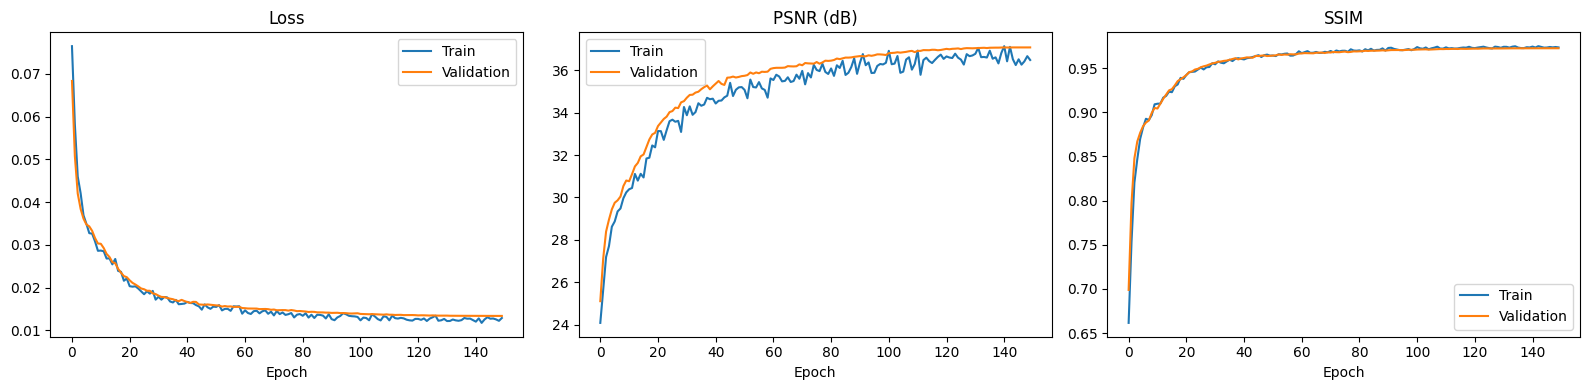

In [11]:
#@title Training curves
fig, axs = plt.subplots(1, 3, figsize=(16, 4))

axs[0].plot(history['train_loss'], label='Train')
axs[0].plot(history['val_loss'], label='Validation')
axs[0].set_title('Loss')
axs[0].set_xlabel('Epoch')
axs[0].legend()

axs[1].plot(history['train_psnr'], label='Train')
axs[1].plot(history['val_psnr'], label='Validation')
axs[1].set_title('PSNR (dB)')
axs[1].set_xlabel('Epoch')
axs[1].legend()

axs[2].plot(history['train_ssim'], label='Train')
axs[2].plot(history['val_ssim'], label='Validation')
axs[2].set_title('SSIM')
axs[2].set_xlabel('Epoch')
axs[2].legend()

plt.tight_layout()
plt.show()


In [12]:
#@title Baseline vs restored-image evaluation
def evaluate(loader, model=None):
    loss_m, psnr_m, ssim_m = AverageMeter(), AverageMeter(), AverageMeter()

    if model is not None:
        model.eval()

    with torch.inference_mode():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            pred = y if model is None else model(y)
            loss = criterion(pred, x)
            psnr_val, ssim_val = compute_metrics(pred, x)

            n = x.size(0)
            loss_m.update(loss.item(), n)
            psnr_m.update(psnr_val, n)
            ssim_m.update(ssim_val, n)

    return {'loss': loss_m.avg, 'psnr': psnr_m.avg, 'ssim': ssim_m.avg}

final_loader = test_loader if test_loader is not None else val_loader
final_split = 'TEST' if test_loader is not None else 'VALIDATION (no independent test folder found)'

baseline = evaluate(final_loader, model=None)
restored = evaluate(final_loader, model=model)

print(final_split)
print(f"Input baseline  | Loss {baseline['loss']:.7f} | PSNR {baseline['psnr']:.2f} dB | SSIM {baseline['ssim']:.3f}")
print(f"Restored model  | Loss {restored['loss']:.7f} | PSNR {restored['psnr']:.2f} dB | SSIM {restored['ssim']:.3f}")
print(f"PSNR gain       | {restored['psnr'] - baseline['psnr']:+.2f} dB")


VALIDATION (no independent test folder found)
Input baseline  | Loss 0.0783780 | PSNR 24.15 dB | SSIM 0.637
Restored model  | Loss 0.0134050 | PSNR 37.07 dB | SSIM 0.972
PSNR gain       | +12.92 dB


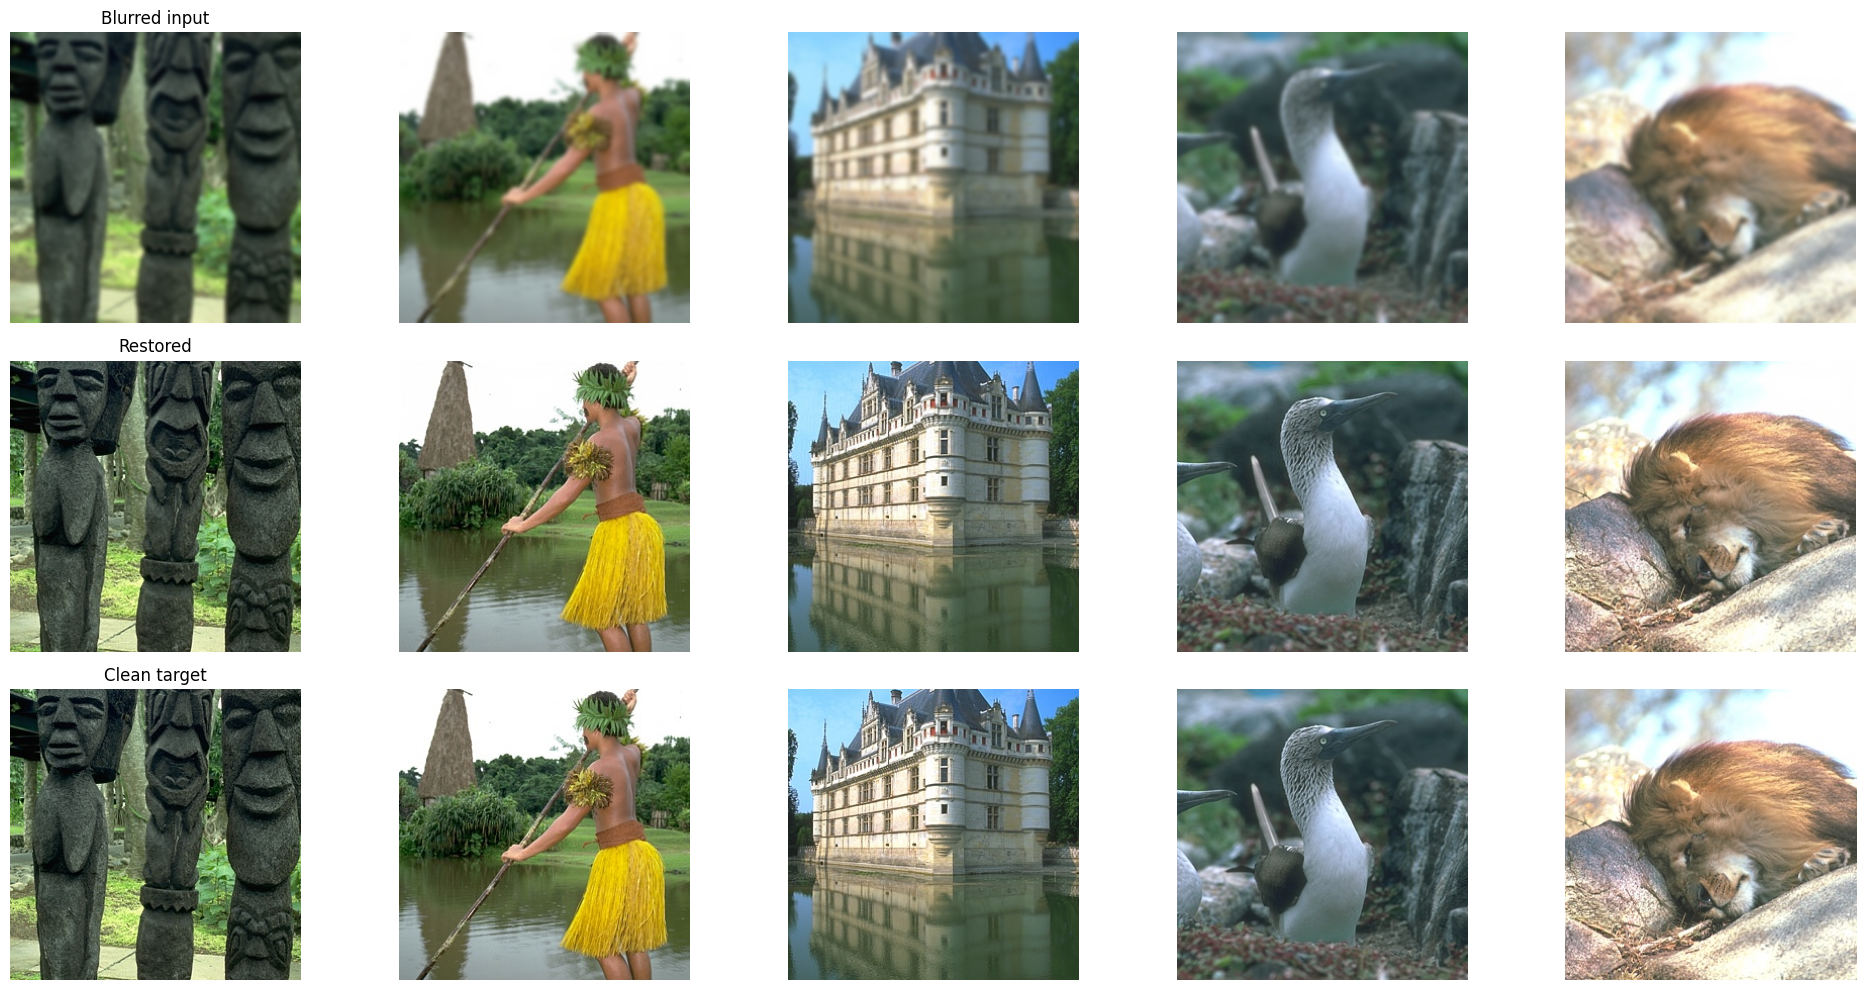

In [13]:
#@title Visual inference
loader = test_loader if test_loader is not None else val_loader
num_images = min(5, len(loader))
fig, axs = plt.subplots(3, num_images, figsize=(4*num_images, 10))
axs = np.array(axs).reshape(3, num_images)

model.eval()
with torch.inference_mode():
    for i, (x, y) in enumerate(loader):
        if i >= num_images:
            break
        pred = model(y.to(device)).cpu().clamp(0, 1)
        show_tensor(y[0], axs[0, i], 'Blurred input' if i == 0 else None)
        show_tensor(pred[0], axs[1, i], 'Restored' if i == 0 else None)
        show_tensor(x[0], axs[2, i], 'Clean target' if i == 0 else None)

plt.tight_layout()
plt.show()


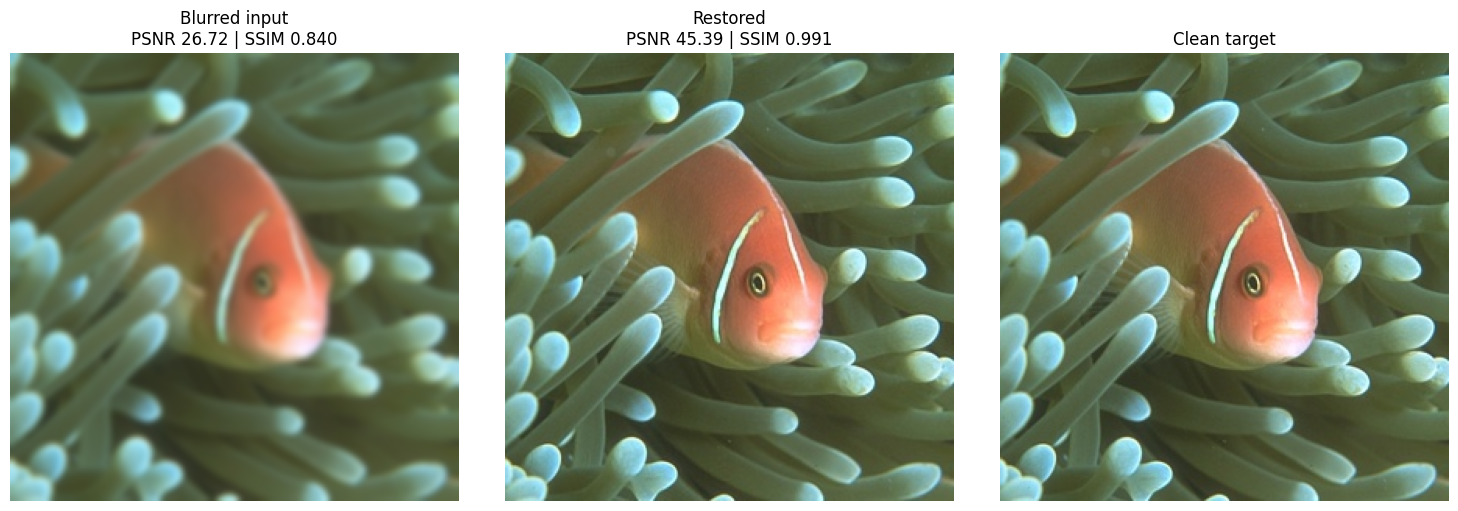

In [19]:
def show_result(index, loader=None, show_metrics=True):
    loader = loader or (test_loader if test_loader is not None else val_loader)
    dataset = loader.dataset

    x, y = dataset[index]                      # x = original, y = blurred
    model.eval()
    with torch.inference_mode():
        pred = model(y.unsqueeze(0).to(device)).cpu().clamp(0, 1)[0]

    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    titles = ['Blurred input', 'Restored', 'Clean target']
    imgs = [y, pred, x]

    if show_metrics:
        psnr_b, ssim_b = compute_metrics(y.unsqueeze(0), x.unsqueeze(0))
        psnr_r, ssim_r = compute_metrics(pred.unsqueeze(0), x.unsqueeze(0))
        titles[0] += f'\nPSNR {psnr_b:.2f} | SSIM {ssim_b:.3f}'
        titles[1] += f'\nPSNR {psnr_r:.2f} | SSIM {ssim_r:.3f}'

    for ax, img, t in zip(axs, imgs, titles):
        show_tensor(img, ax, t)
    plt.tight_layout()
    plt.show()

# Examples
show_result(39)